# Meshal Mahnoor | YOLO

You only live(look ;D) once, so I am now creating a roboflow enviornment and then getting my uno cards, because your opponent only can look at your cards once when you allow haha

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="redacted") #this is my secret api key maam :))))
project = rf.workspace("joseph-nelson").project("uno-cards")
version = project.version(3)
dataset = version.download("yolo26")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 93.0 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Uno-Cards-3 in yolo26:: 100%|██████████| 68352/68352 [00:10<00:00, 6710.22it/s]


Now lets get YOLO 26 small as there are small numbers to detect so, lets load the model:

In [ ]:
!pip install -q ultralytics
from ultralytics import YOLO
from PIL import Image

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
model = YOLO("yolo26s.pt")
print("Number of classes: ", {len(model.names)})
print(model.names)

Number of classes:  {80}
{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 

Lets now get our image data through the yaml file

In [ ]:
#I am going to get the path of the images through the roboflow project
from pathlib import Path
import yaml

dataset_dir = Path("Uno-Cards-3").resolve()
yaml_path = dataset_dir / "data.yaml"

with open(yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

data_cfg["path"] = str(dataset_dir)
data_cfg["train"] = "train/images"
data_cfg["val"] = "valid/images"
if (dataset_dir / "test/images").exists():
    data_cfg["test"] = "test/images"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

print(f"Loaded {len(data_cfg['names'])} classes:", data_cfg["names"])

Loaded 15 classes: ['0', '1', '10', '11', '12', '13', '14', '2', '3', '4', '5', '6', '7', '8', '9']


In [ ]:
import cv2
dataset_dir = Path("Uno-Cards-3").resolve()
with open(dataset_dir / "data.yaml") as f:
    class_names = yaml.safe_load(f)["names"]

img_path = next((dataset_dir / "train/images").glob("*.jpg"))
label_path = dataset_dir / "train/labels" / f"{img_path.stem}.txt"

img = cv2.imread(str(img_path))
h, w, _ = img.shape

with open(label_path) as f:
    for line in f:
        cls_id, xc, yc, bw, bh = map(float, line.split())
        x1 = int((xc - bw / 2) * w)
        y1 = int((yc - bh / 2) * h)
        x2 = int((xc + bw / 2) * w)
        y2 = int((yc + bh / 2) * h)
        label = class_names[int(cls_id)]

        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, label, (x1, max(y1 - 8, 0)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

cv2.imwrite("sample_check.jpg", img)
print("Saved visualization to sample_check.jpg")

Saved visualization to sample_check.jpg


Train my YOLO model:

In [ ]:
model.train(
    data = "/content/Uno-Cards-3/data.yaml",
    fraction = [1600,400],
    batch = 16,
    epochs = 32,
    patience = 10,
    project = "uno_card_detection",
    imgsz = 640,
    name = "uno-cards"
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Uno-Cards-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=32, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=[1600, 400], freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=uno-cards, nbs=64, nms=None, opset=None, optimize=

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a59741ba120>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,   

In [ ]:
metrics = model.val()
print ("map50", metrics.box.map50)
print("map50-95", metrics.box.map)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,470,985 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 189.1±402.6 MB/s, size: 39.5 KB)
val: Scanning /content/Uno-Cards-3/valid/labels... 1798 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1798/1798 830.1it/s 2.2s
val: New cache created: /content/Uno-Cards-3/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 113/113 3.9it/s 29.3s
                   all       1798       5394      0.996      0.995      0.991      0.809
                     0        352        370          1      0.998      0.995      0.844
                     1        348        374          1      0.987      0.995      0.816
                    10        330        346      0.999          1      0.995      0.809
                    11        343        367      0.999          1

Lets infer using one of our images from the dataset:


image 1/1 /content/Uno-Cards-3/test/images/000617146_jpg.rf.24ee0aefcb141c7e36cfa000c2a51a1b.jpg: 640x640 1 0, 1 2, 1 7, 16.5ms
Speed: 4.0ms preprocess, 16.5ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict


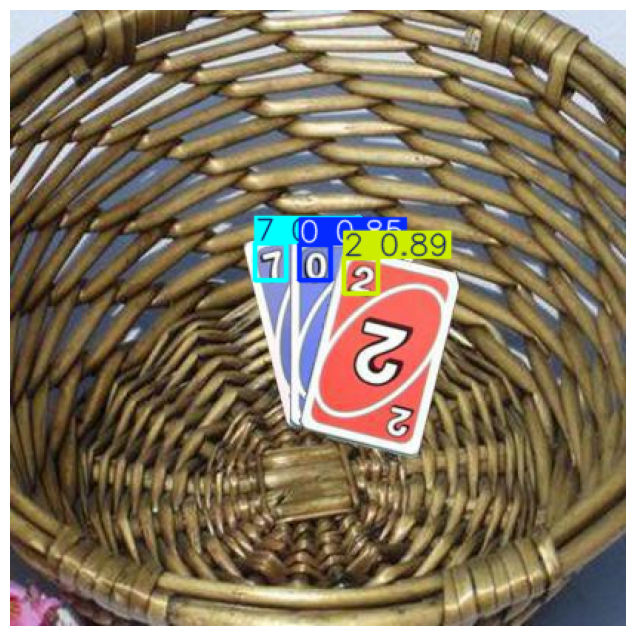

In [ ]:
import matplotlib.pyplot as plt
model = YOLO("/content/runs/detect/uno_card_detection/uno-cards/weights/best.pt")

results = model.predict(
    source="/content/Uno-Cards-3/test/images/000617146_jpg.rf.24ee0aefcb141c7e36cfa000c2a51a1b.jpg",
    conf=0.40,
    save=True
)
plt.figure(figsize=(8, 8))
plt.imshow(results[0].plot()[..., ::-1])
plt.axis("off")
plt.show()